# EDA 8 — Further case-flow decompositions (Supporting Information, Appendix S2)

Produces one Supporting Information figure with the further cases referred to in Section 4.2.
Camden 026 and Croydon 044 are drawn in the main text by `eda_7_flow_mechanism_camde-croydon_case.py`
and are not repeated here.

**Inputs:** `outputs/msoa_cascade_national_frame_20260625.csv`, `outputs/eda4_results_for_phase3_20260626.csv`,
`outputs/eda9_mechanism_tree_20260705.csv` (profile labels), `data/MSOA_2011_to_2021_lookup_for_identification.csv` (names).

In every panel:
- inflows enter on the left and outflows leave on the right;
- ribbon width is proportional to recorded person-moves;
- dark red / pale red show cascade-direction flows within London / crossing the London boundary;
- dark blue / pale blue show escalator-direction flows within London / crossing the London boundary.

Purple is reserved for Yee and Dennett attribute labels elsewhere in the chapter and is therefore not used for flow arms.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.path import Path
from matplotlib.patches import PathPatch
 
plt.rcParams['font.family'] = 'DejaVu Sans'

from pyprojroot import here

ROOT = here()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from flow_yee_palette_v2 import ALLUVIAL


In [2]:

ROOT       = here()
sys.path.insert(0, str(ROOT))

DATA_DIR   = ROOT / 'data'
OUT_DIR    = ROOT / 'outputs' / 'case_study' / 'si_appendix_s2'
NAT  = ROOT / 'outputs' / 'msoa_cascade_national_frame_20260625.csv'
EDA4 = ROOT / 'outputs' / 'eda4_results_for_phase3_20260626.csv'
EDA9 = ROOT / 'outputs' / 'eda9_mechanism_tree_20260705.csv'
LOOKUP = DATA_DIR / 'MSOA_2011_to_2021_lookup_for_identification.csv'
EXT_DECILE = 6                                   # synthetic external node sits at national D6
YL = 3.05

OUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Chapter-wide colour grammar imported from flow_yee_palette_v2.py
C_IN = ALLUVIAL['cascade_in']
C_EX = ALLUVIAL['cascade_ex']
K_IN = ALLUVIAL['counter_in']
K_EX = ALLUVIAL['counter_ex']

BAR  = '#2f2f2f'
ZONE = '#f2f0ec'          # rest-of-England margin shading
BND  = '#8a8a8a'          # boundary dash colour


In [4]:
# ── x-geometry ──────────────────────────────────────────────────────────
X_EXT_L = -1.05   # external ribbons start here (left)
X_BND_L =  0.30   # London boundary, left
X_ML    =  3.30   # MSOA bar left edge
X_MR    =  3.90   # MSOA bar right edge
X_BND_R =  6.90   # London boundary, right
X_EXT_R =  8.25   # external ribbons end here (right)
 
INNER_LONDON = {
    'Camden','City of London','Greenwich','Hackney','Hammersmith and Fulham',
    'Haringey','Islington','Kensington and Chelsea','Lambeth','Lewisham',
    'Newham','Southwark','Tower Hamlets','Wandsworth','Westminster',
}

In [5]:
def _band(ax, x0, x1, lo, hi, color):
    ax.add_patch(mpatches.Rectangle((x0, lo), x1-x0, hi-lo,
                                    facecolor=color, edgecolor='none',
                                    alpha=0.92, zorder=3))

In [6]:
def _chevron(ax, xc, yc, h):
    """White right-pointing chevron centred at (xc, yc); h = band height."""
    s = min(h*0.55, 0.14)
    if s < 0.045: return
    w = s * 0.9
    verts = [(xc-w/2, yc+s), (xc+w/2, yc), (xc-w/2, yc-s),
             (xc-w/2+w*0.45, yc), (xc-w/2, yc+s)]
    ax.add_patch(PathPatch(Path(verts, closed=True), facecolor='white',
                           edgecolor='none', alpha=0.85, zorder=4))

In [7]:
def _lay(segs, gap, scale):
    hs = [(v/scale, c, n, x0, x1) for v, c, n, x0, x1 in segs]
    tot = sum(h for h, *_ in hs) + gap*(sum(1 for _, _, n, _, _ in hs if n) - 1)
    top = tot/2; out = []
    for i, (h, c, n, x0, x1) in enumerate(hs):
        if n and i > 0: top -= gap
        out.append((top-h, top, c, x0, x1)); top -= h
    return out

In [8]:
def arms_split(r, yr):
    d  = r['Wealth_Decile_National']
    ei, eo = r[f'Ext_Inflow_nat_{yr}'], r[f'Ext_Outflow_nat_{yr}']
    iw, op = r[f'Inflow_Wealthier_nat_{yr}'], r[f'Outflow_Poorer_nat_{yr}']
    ip, ow = r[f'Inflow_Poorer_nat_{yr}'],    r[f'Outflow_Wealthier_nat_{yr}']
    e_iw = ei if d < EXT_DECILE else 0; e_ip = ei if d > EXT_DECILE else 0
    e_ow = eo if d < EXT_DECILE else 0; e_op = eo if d > EXT_DECILE else 0
    return dict(iw=iw, op=op, ip=ip, ow=ow, iw_e=e_iw, op_e=e_op, ip_e=e_ip, ow_e=e_ow,
                iw_i=iw-e_iw, op_i=op-e_op, ip_i=ip-e_ip, ow_i=ow-e_ow)

In [9]:
def panel(ax, r, yr, scale, title, dom_lon, show_headers=True):
    a = arms_split(r, yr); gap = 0.30
 
    # background: rest-of-England margins + boundary dashes
    ax.add_patch(mpatches.Rectangle((X_EXT_L-0.55, -YL), X_BND_L-(X_EXT_L-0.55), 2*YL,
                                    facecolor=ZONE, edgecolor='none', zorder=0))
    ax.add_patch(mpatches.Rectangle((X_BND_R, -YL), (X_EXT_R+0.55)-X_BND_R, 2*YL,
                                    facecolor=ZONE, edgecolor='none', zorder=0))
    for xb in (X_BND_L, X_BND_R):
        ax.plot([xb, xb], [-YL*0.88, YL*0.80], ls=(0,(4,3)), lw=0.9, color=BND, zorder=1)
    ax.text(X_BND_L, -YL*0.96, 'London boundary', ha='center', va='top',
            fontsize=5.8, color=BND)
    ax.text(X_BND_R, -YL*0.96, 'London boundary', ha='center', va='top',
            fontsize=5.8, color=BND)
    ax.text((X_EXT_L-0.55+X_BND_L)/2, -YL*0.80, 'rest of\nEngland', ha='center',
            va='center', fontsize=5.8, color='#9a9a9a', style='italic')
    ax.text((X_BND_R+X_EXT_R+0.55)/2, -YL*0.80, 'rest of\nEngland', ha='center',
            va='center', fontsize=5.8, color='#9a9a9a', style='italic')
 
    # segments now carry their own x-extent: internal stops at the boundary,
    # external crosses it
    Lsegs = [(a['iw_i'], C_IN, True,  X_BND_L, X_ML),
             (a['iw_e'], C_EX, False, X_EXT_L, X_ML),
             (a['ip_i'], K_IN, True,  X_BND_L, X_ML),
             (a['ip_e'], K_EX, False, X_EXT_L, X_ML)]
    Rsegs = [(a['ow_i'], K_IN, True,  X_MR, X_BND_R),
             (a['ow_e'], K_EX, False, X_MR, X_EXT_R),
             (a['op_i'], C_IN, True,  X_MR, X_BND_R),
             (a['op_e'], C_EX, False, X_MR, X_EXT_R)]
    L, R = _lay(Lsegs, gap, scale), _lay(Rsegs, gap, scale)
 
    for lo, hi, c, x0, x1 in L:
        _band(ax, x0, x1, lo, hi, c)
        _chevron(ax, X_ML-0.55, (lo+hi)/2, hi-lo)          # arrows into the bar
    for lo, hi, c, x0, x1 in R:
        _band(ax, x0, x1, lo, hi, c)
        _chevron(ax, x1-0.45, (lo+hi)/2, hi-lo)            # arrows exiting
 
    bar_lo, bar_hi = min(L[-1][0], R[-1][0]), max(L[0][1], R[0][1])
    ax.add_patch(mpatches.Rectangle((X_ML, bar_lo), X_MR-X_ML, bar_hi-bar_lo,
                                    facecolor=BAR, edgecolor='none', zorder=5))
 
    # arm labels + counts, anchored at the OUTER end of each arm
    iw_c=(L[0][0]+L[1][1])/2; ip_c=(L[2][0]+L[3][1])/2
    ow_c=(R[0][0]+R[1][1])/2; op_c=(R[2][0]+R[3][1])/2
    def lab(x, y, name, tot, ext, c, ha):
        if tot/scale < 0.03: return
        ax.text(x, y+0.085, name, ha=ha, va='bottom', fontsize=6.4,
                color=c, fontweight='bold')
        ax.text(x, y-0.075, f'{int(tot)}'+(f' (ext {int(ext)})' if ext > 0.5 else ''),
                ha=ha, va='top', fontsize=6.8, color=c)
    lab(X_EXT_L-0.68, iw_c, 'from wealthier', a['iw'], a['iw_e'], C_IN, 'right')
    lab(X_EXT_L-0.68, ip_c, 'from poorer',    a['ip'], a['ip_e'], K_IN, 'right')
    lab(X_EXT_R+0.68, ow_c, 'to wealthier',   a['ow'], a['ow_e'], K_IN, 'left')
    lab(X_EXT_R+0.68, op_c, 'to poorer',      a['op'], a['op_e'], C_IN, 'left')
 
    # direction headers, drawn on the plot itself
    if show_headers:
        ax.text((X_EXT_L+X_ML)/2, YL*0.90, 'I N F L O W S  \u25b6',
                ha='center', va='center', fontsize=7.6, color='#555',
                fontweight='bold')
        ax.text((X_MR+X_EXT_R)/2, YL*0.90, '\u25b6  O U T F L O W S',
                ha='center', va='center', fontsize=7.6, color='#555',
                fontweight='bold')
 
    # geography chip: ring + national decile
    ring = 'Inner' if r['ladnm'] in INNER_LONDON else 'Outer'
    ax.text(0.99, 0.985, f"{ring} London \u00b7 nat D{int(r['Wealth_Decile_National'])}",
            transform=ax.transAxes, ha='right', va='top', fontsize=6.6,
            color='#444',
            bbox=dict(boxstyle='round,pad=0.32', fc='white', ec='#cfcfcf', lw=0.7))
 
    casc, cnt = a['iw']+a['op'], a['ip']+a['ow']; dom = casc/(casc+cnt)
    infl = a['iw']/(a['iw']+a['op']) if (a['iw']+a['op']) else np.nan
    ext_sh = (a['iw_e']+a['ip_e']+a['ow_e']+a['op_e'])/(casc+cnt) if (casc+cnt) else 0
    ax.text(0.5, -0.045, f'dominance(nat) {dom:.2f}   inflow share {infl:.2f}   '
            f'external(cross-decile) {ext_sh:.0%}   \u00b7   dominance(London) {dom_lon:.2f}',
            transform=ax.transAxes, ha='center', va='top', fontsize=8,
            color=C_IN if dom >= 0.5 else K_IN, fontweight='bold')
    ax.text(0.5, 1.0, title, transform=ax.transAxes, ha='center', va='bottom',
            fontsize=10, fontweight='bold')
    ax.set_xlim(X_EXT_L-2.55, X_EXT_R+2.55); ax.set_ylim(-YL, YL)
    ax.set_axis_off()

In [10]:
nat = pd.read_csv(NAT)
e4 = pd.read_csv(EDA4)

domA = lambda c, yr: e4.loc[e4['msoa11cd'].eq(c), f'Dom_A_{yr}'].iloc[0]
row  = lambda c: nat.loc[nat['msoa11cd'].eq(c)].iloc[0]

# Resolve named cases reproducibly instead of hard-coding an uncertain code.
lookup = pd.read_csv(LOOKUP, encoding='utf-8-sig')
code_candidates = ['MSOA11CD', 'msoa11cd']
name_candidates = ['MSOA11NM', 'MSOA11HCLNM', 'msoa11nm', 'msoa11hclnm']
code_col = next((c for c in code_candidates if c in lookup.columns), None)
name_col = next((c for c in name_candidates if c in lookup.columns), None)
if code_col is None or name_col is None:
    raise KeyError(f'Could not identify MSOA code/name columns in {LOOKUP.name}: {list(lookup.columns)}')

def resolve_msoa(name):
    hit = lookup.loc[lookup[name_col].astype(str).str.casefold().eq(name.casefold()), code_col].dropna().unique()
    if len(hit) != 1:
        raise ValueError(f'Expected exactly one code for {name!r}; found {hit.tolist()}')
    return hit[0]

WESTMINSTER_019 = resolve_msoa('Westminster 019')
print('Westminster 019:', WESTMINSTER_019)


Westminster 019: E02000978


In [11]:
def figscale(cases):
    m = 0
    for c, _ in cases:
        r = row(c)
        for yr in ['11','21']:
            a = arms_split(r, yr); m = max(m, a['iw']+a['ip'], a['ow']+a['op'])
    return m/3.0

In [12]:
LEG = [
    mpatches.Patch(color=C_IN, label='Cascade direction · within London'),
    mpatches.Patch(color=C_EX, label='Cascade direction · crossing London boundary'),
    mpatches.Patch(color=K_IN, label='Escalator direction · within London'),
    mpatches.Patch(color=K_EX, label='Escalator direction · crossing London boundary'),
]

In [13]:
# Profile labels in the article's wording, read from the eda_6 tree export
tree = pd.read_csv(EDA9).set_index('msoa11cd')
PROFILE_LABEL = {'inflow-driven': 'inflow-driven, frame-robust',
                 'frame-sensitive inflow': 'frame-sensitive inflow',
                 'outflow: internal-majority': 'outflow-internal-majority',
                 'outflow: external-majority': 'outflow-external-majority'}
REGIME_LABEL = {'Counter-led': 'Escalator-led'}      # code name -> article name

def profile_label(code, yr):
    """Mechanism profile in that window, or the Frame C regime if not Cascade-led."""
    leaf = tree.loc[code, f'leaf_{yr}']
    if isinstance(leaf, str):
        return PROFILE_LABEL[leaf]
    regime = tree.loc[code, f'Typ_C_{yr}']
    return f'{REGIME_LABEL.get(regime, regime)} (Frame C)'


def build(title, cases, fname, caption='', figsize_per_row=3.25, dpi=180):
    sc = figscale(cases)
    nr = len(cases)
    fig, axes = plt.subplots(nr, 2, figsize=(14, figsize_per_row * nr + 1.5), squeeze=False)
    for i, (code, name) in enumerate(cases):
        for j, yr in enumerate(('11', '21')):
            panel(axes[i, j], row(code), yr, sc,
                  f'{name}  ·  20{yr}  ·  {profile_label(code, yr)}',
                  domA(code, yr), show_headers=(i == 0))

    fig.suptitle(title, fontsize=13.5, fontweight='bold', y=0.995)
    fig.legend(handles=LEG, loc='lower center', ncol=4, frameon=False,
               fontsize=8.2, bbox_to_anchor=(0.5, 0.006))
    if caption:
        fig.text(0.5, 0.047, caption, ha='center', va='bottom', fontsize=8.1,
                 style='italic', color='#333333', wrap=True)
    plt.tight_layout(rect=[0, 0.072 if caption else 0.04, 1, 0.975])
    out = OUT_DIR / fname
    plt.savefig(out, dpi=dpi, bbox_inches='tight')
    print(f'Saved {out}')
    plt.show()

Tower Hamlets 010  2011: inflow-driven, frame-robust    2021: inflow-driven, frame-robust
Westminster 019    2011: outflow-internal-majority      2021: outflow-internal-majority
Harrow 008         2011: outflow-internal-majority      2021: outflow-internal-majority
Saved /Users/xing/Desktop/publication/master-dissertation/dissertation-manuscript-replication/outputs/case_study/si_appendix_s2/si_further_flow_decompositions.png


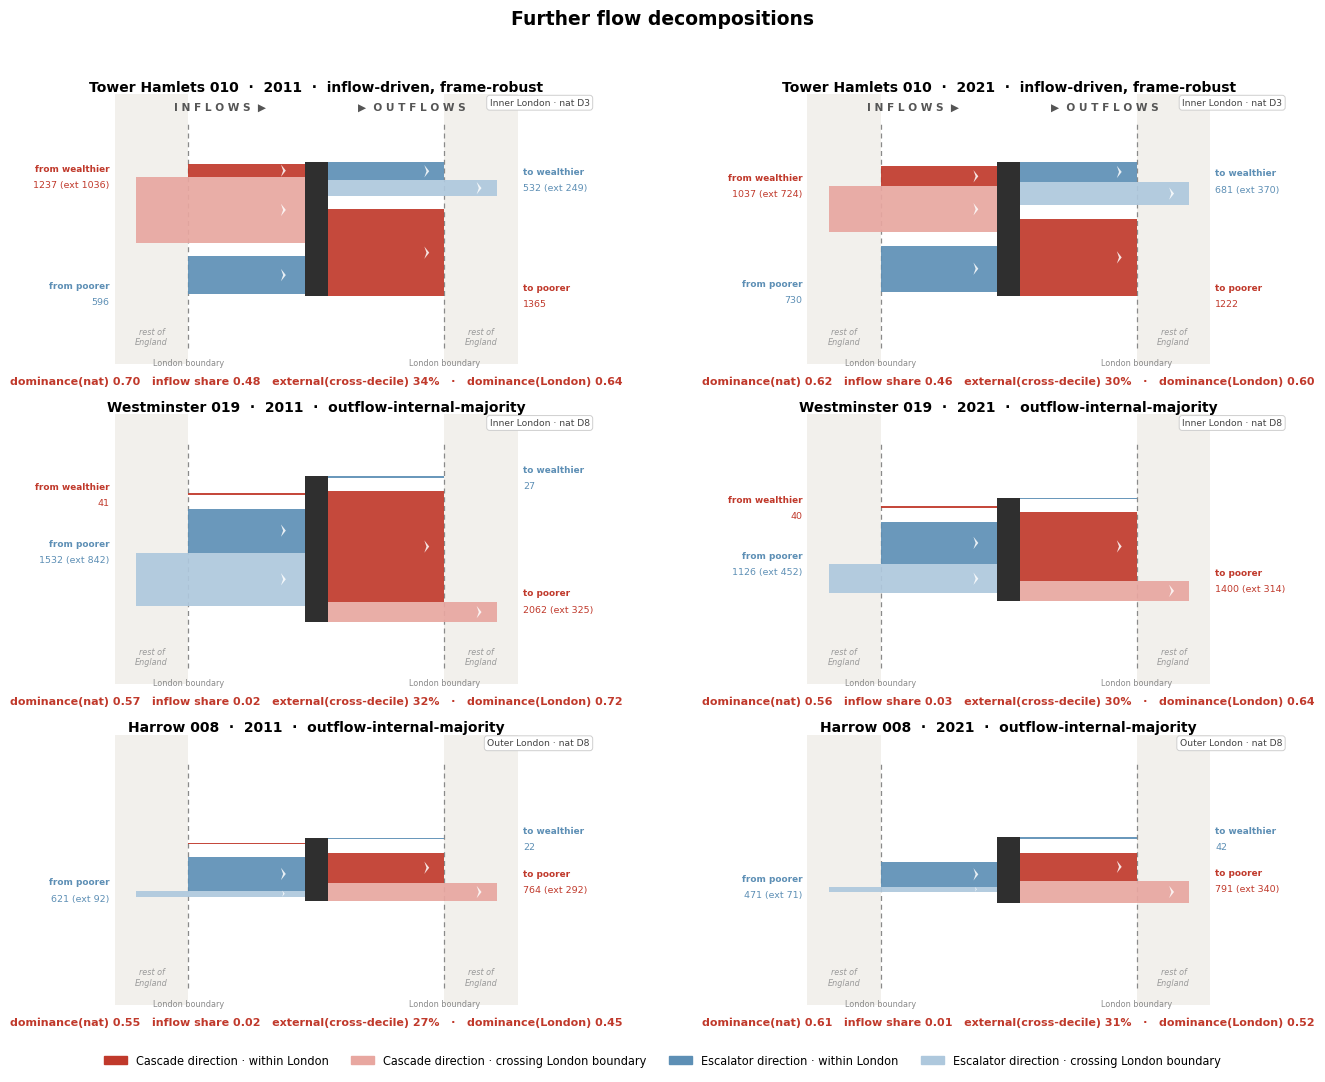

In [14]:
# ── case roster for Supporting Information, Appendix S2 ───────────────────
# Camden 026 and Croydon 044 appear in the main text (eda_7), so they are not repeated.
CASES_SI = [
    ('E02000873',     'Tower Hamlets 010'),   # inflow-driven, frame-robust (compare Camden 026)
    (WESTMINSTER_019, 'Westminster 019'),     # outflow-internal-majority, Inner London
    ('E02000440',     'Harrow 008'),          # outflow-internal-majority, Outer London
]

# Check each case's profile in this run before writing the SI text.
for code, name in CASES_SI:
    print(f"{name:18s} 2011: {profile_label(code, '11'):30s} 2021: {profile_label(code, '21')}")

build('Further flow decompositions', CASES_SI,
      'si_further_flow_decompositions.png', figsize_per_row=3.10)

## Placement

- **Supporting Information, Appendix S2:** the figure above, with the reading guide (what the
  ribbons, colours and summary measures mean) and one short paragraph per case.
- **Main text, Section 4.2:** Camden 026 and Croydon 044 only, from `eda_7`.